# ⚡ 03. Parallel Multi-Analysis Workflow with LangGraph

Welcome to **Project 03: Parallel Multi-Analysis Workflow**!

In traditional agentic systems, tasks often run **sequentially** (Node A $\rightarrow$ Node B $\rightarrow$ Node C), which introduces cumulative latency. When multiple analysis tasks are **independent** and operate on the exact same input, running them in parallel significantly improves performance and responsiveness.

---

## 🎯 What You Will Learn
1. **Fan-Out Architecture**: Dispatching a single input to multiple independent worker nodes simultaneously.
2. **Fan-In Architecture**: Synchronizing and aggregating results from parallel branches into a single synthesis node.
3. **State Management**: Defining a shared `TypedDict` state where parallel nodes safely update their assigned keys.
4. **Graph Compilation & Visualization**: Compiling the workflow and rendering its topological structure.
5. **Streaming Concurrency (`graph.stream()`)**: Observing real-time parallel node completions as they occur.

---

## 🔄 Architecture Overview

```text
                              START
                                │
                ┌───────────────┼───────────────┐
                │ (Fan-Out)     │               │
                ▼               ▼               ▼
           Sentiment        Keywords         Summary
            Analysis        Extraction      Generation
                │               │               │
                └───────────────┼───────────────┘
                                │ (Fan-In)
                                ▼
                           Merge Results
                                │
                                ▼
                               END
```

## 1. Setup & Environment Variables

We load API keys from the `.env` file and initialize the **Google Gemini** model via `ChatGoogleGenerativeAI`.

In [3]:
# Install dependencies if running in a fresh environment:
# !pip install -r requirements.txt

import os
from dotenv import load_dotenv

# Load environment variables from .env file
load_dotenv()

# Verify that Google API Key is present
google_api_key = os.getenv("GOOGLE_API_KEY")
print(f"✓ Google API Key configured: {bool(google_api_key)}")
if not google_api_key:
    print("⚠️ Please add your GOOGLE_API_KEY in the .env file to run LLM invocations.")

✓ Google API Key configured: True


## 2. Initialize Language Model & Helpers

We configure `gemini-2.5-flash` with low temperature for deterministic and fast extraction.
We also define a helper function `extract_text` to safely parse LLM output and avoid formatting quirks.

In [4]:
from langchain_google_genai import ChatGoogleGenerativeAI
from IPython.display import display, Markdown, Image

# Initialize Google Gemini Chat Model
# gemini-2.5-flash offers ultra-low latency and reliable structured performance
llm = ChatGoogleGenerativeAI(
    model="gemini-3.7-flash",
    temperature=0.1
)

def extract_text(content) -> str:
    """
    Safely extracts clean plain text from LangChain message responses,
    handling strings, list structures, and metadata gracefully.
    """
    if isinstance(content, str):
        return content.strip()
    elif isinstance(content, list):
        parts = []
        for part in content:
            if isinstance(part, dict) and part.get("type") == "text":
                parts.append(part.get("text", ""))
            elif isinstance(part, str):
                parts.append(part)
        return "\n".join(parts).strip()
    return str(content).strip()

print("✓ Model and helper utilities initialized successfully.")

✓ Model and helper utilities initialized successfully.


## 3. Define the Graph State Schema

LangGraph uses a shared State across all nodes. In Python, we represent this with `TypedDict`.

### State Keys:
- `input_text`: The raw text to be analyzed.
- `sentiment`: The emotional tone and polarity evaluation.
- `keywords`: List of key terms and entities extracted.
- `summary`: A concise synthesis of the main ideas.
- `final_analysis`: The merged executive report synthesized from all parallel branches.

In [5]:
from typing import TypedDict, List, Optional

class ContentAnalysisState(TypedDict):
    """
    Shared state schema for parallel content analysis.
    Each parallel node updates only its dedicated key.
    """
    input_text: str                     # Input text provided by user
    sentiment: Optional[str]            # Populated by Sentiment Analysis Node
    keywords: Optional[List[str]]       # Populated by Keyword Extraction Node
    summary: Optional[str]              # Populated by Summarization Node
    final_analysis: Optional[str]       # Populated by Merge Node (Fan-In)

print("✓ ContentAnalysisState schema defined.")

✓ ContentAnalysisState schema defined.


## 4. Define Parallel Analysis Nodes (Fan-Out)

We create three specialized, decoupled worker nodes. Notice how each node:
1. Reads `state["input_text"]`.
2. Executes an independent LLM prompt.
3. Returns a dictionary containing **only** the field it is responsible for updating.

In [6]:
from langchain_core.messages import SystemMessage, HumanMessage

def sentiment_analysis_node(state: ContentAnalysisState) -> dict:
    """
    Parallel Node 1: Evaluates the emotional tone, polarity, and nuances of the input text.
    """
    input_text = state["input_text"]
    
    messages = [
        SystemMessage(
            content=(
                "You are an expert Sentiment and Tone Analyzer. "
                "Analyze the emotional tone of the given text. Classify it as Positive, Negative, Neutral, or Mixed. "
                "Provide a concise 1-2 sentence justification with confidence score (e.g., High/Medium/Low)."
            )
        ),
        HumanMessage(content=f"Analyze the sentiment of the following text:\n\n{input_text}")
    ]
    
    response = llm.invoke(messages)
    sentiment_result = extract_text(response.content)
    
    # Return only the sentiment key to update state
    return {"sentiment": sentiment_result}


def keyword_extraction_node(state: ContentAnalysisState) -> dict:
    """
    Parallel Node 2: Identifies the most significant keywords, entities, and topics.
    """
    input_text = state["input_text"]
    
    messages = [
        SystemMessage(
            content=(
                "You are a precise Keyword and Entity Extractor. "
                "Extract the top 5-8 most important keywords, technical concepts, or named entities from the text. "
                "Output them as a comma-separated list without numbering or extra commentary."
            )
        ),
        HumanMessage(content=f"Extract keywords from the following text:\n\n{input_text}")
    ]
    
    response = llm.invoke(messages)
    raw_keywords = extract_text(response.content)
    
    # Parse comma-separated string into a clean list of strings
    keywords_list = [k.strip() for k in raw_keywords.split(",") if k.strip()]
    
    # Return only the keywords key to update state
    return {"keywords": keywords_list}


def summarization_node(state: ContentAnalysisState) -> dict:
    """
    Parallel Node 3: Generates a concise, high-yield summary of the original content.
    """
    input_text = state["input_text"]
    
    messages = [
        SystemMessage(
            content=(
                "You are a concise Executive Summarizer. "
                "Distill the core message of the text into 2-3 clear, impactful sentences. "
                "Focus strictly on key takeaways without unnecessary filler."
            )
        ),
        HumanMessage(content=f"Summarize the following text:\n\n{input_text}")
    ]
    
    response = llm.invoke(messages)
    summary_result = extract_text(response.content)
    
    # Return only the summary key to update state
    return {"summary": summary_result}

print("✓ Parallel analysis nodes (Sentiment, Keywords, Summary) defined.")

✓ Parallel analysis nodes (Sentiment, Keywords, Summary) defined.


## 5. Define Merge Node (Fan-In)

The **Merge Node** runs only after **all three parallel nodes** have finished.
It reads `state["sentiment"]`, `state["keywords"]`, and `state["summary"]` to produce a unified, structured final report.

In [7]:
def merge_results_node(state: ContentAnalysisState) -> dict:
    """
    Fan-In Node: Combines the parallel findings (sentiment, keywords, summary)
    into a polished, structured executive analysis.
    """
    sentiment = state.get("sentiment", "N/A")
    keywords = state.get("keywords", [])
    summary = state.get("summary", "N/A")
    keywords_str = ", ".join(keywords) if keywords else "N/A"
    
    messages = [
        SystemMessage(
            content=(
                "You are an Executive Intelligence Analyst. "
                "Your job is to synthesize three independent analysis inputs into a single, cohesive, "
                "well-structured Markdown report.\n\n"
                "Use clear sections, including:\n"
                "- 📋 **Executive Overview**\n"
                "- 🎭 **Sentiment & Tone Assessment**\n"
                "- 🔑 **Key Themes & Topics**\n"
                "- 💡 **Strategic Takeaways / Action Items**"
            )
        ),
        HumanMessage(
            content=(
                f"Here are the analysis components to merge:\n\n"
                f"### 1. Summary Analysis:\n{summary}\n\n"
                f"### 2. Sentiment Analysis:\n{sentiment}\n\n"
                f"### 3. Extracted Keywords:\n{keywords_str}\n\n"
                f"Synthesize these into the final structured report."
            )
        )
    ]
    
    response = llm.invoke(messages)
    final_report = extract_text(response.content)
    
    return {"final_analysis": final_report}

print("✓ Merge node (Fan-In) defined.")

✓ Merge node (Fan-In) defined.


## 6. Build and Compile the LangGraph Workflow

Now we wire together the **Fan-Out** and **Fan-In** graph structure:
1. Add nodes to `StateGraph`.
2. Add edges from `START` to `sentiment_analysis`, `keyword_extraction`, and `summarization` (**Fan-Out**).
3. Add edges from each worker node to `merge_results` (**Fan-In**).
4. Add edge from `merge_results` to `END`.

In [8]:
from langgraph.graph import StateGraph, START, END

# 1. Initialize StateGraph with our shared state schema
builder = StateGraph(ContentAnalysisState)

# 2. Register all nodes
builder.add_node("sentiment_analysis", sentiment_analysis_node)
builder.add_node("keyword_extraction", keyword_extraction_node)
builder.add_node("summarization", summarization_node)
builder.add_node("merge_results", merge_results_node)

# 3. Fan-Out: Connect START to all three parallel nodes
builder.add_edge(START, "sentiment_analysis")
builder.add_edge(START, "keyword_extraction")
builder.add_edge(START, "summarization")

# 4. Fan-In: Connect all three parallel nodes to the merge node
builder.add_edge("sentiment_analysis", "merge_results")
builder.add_edge("keyword_extraction", "merge_results")
builder.add_edge("summarization", "merge_results")

# 5. Connect Merge Node to END
builder.add_edge("merge_results", END)

# 6. Compile the graph
graph = builder.compile()

print("✓ Graph compiled successfully with Fan-Out and Fan-In architecture!")

✓ Graph compiled successfully with Fan-Out and Fan-In architecture!


## 7. Visualize the Graph Structure

Let's render the compiled graph to visually confirm the parallel branches and synchronization point.

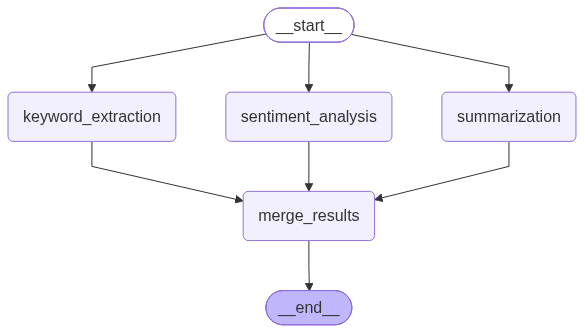

In [9]:
try:
    # Attempt to render visual PNG using Mermaid
    png_data = graph.get_graph().draw_mermaid_png()
    display(Image(png_data))
except Exception as e:
    # Fallback to ascii representation if mermaid rendering backend is unavailable
    print("Mermaid PNG render unavailable, showing text graph schema:")
    print(graph.get_graph().draw_ascii())

## 8. Run Comprehensive Test Cases

We test the workflow on three diverse real-world texts:
1. **Tech Product Announcement** (Exciting, positive tone with technical concepts)
2. **Critical Customer Review / Escalation** (Negative/urgent tone with specific issues)
3. **Scientific Breakthrough Report** (Neutral/objective tone with factual data)

In [10]:
# Test Case 1: Tech Product Announcement
article_1 = """
NextGen Robotics today officially unveiled 'AeroPulse 3000', an autonomous drone delivery system 
powered by state-of-the-art edge AI chips and renewable solar battery cells. During live field trials in Seattle, 
the drone completed 500 consecutive urban package deliveries in sub-zero weather with 99.8% on-time accuracy 
and zero safety incidents. Industry experts praised the revolutionary obstacle avoidance algorithms and 
whisper-quiet rotor design, calling it the most promising leap forward in last-mile logistics in the past decade.
"""

print("Running Test Case 1: Tech Product Launch...")
result_1 = graph.invoke({"input_text": article_1})

# Display individual parallel components and final report cleanly
display(Markdown(f"### 🧪 Parallel Branch Outputs:"))
display(Markdown(f"**1. Sentiment:** {result_1['sentiment']}"))
display(Markdown(f"**2. Extracted Keywords:** `{', '.join(result_1['keywords'])}`"))
display(Markdown(f"**3. Summary:** {result_1['summary']}"))
display(Markdown("---\n### 📊 Final Synthesized Analysis:"))
display(Markdown(result_1["final_analysis"]))

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Running Test Case 1: Tech Product Launch...


Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.
Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


### 🧪 Parallel Branch Outputs:

**1. Sentiment:** **Sentiment:** Positive

**Justification:** The text uses strongly enthusiastic language to describe the successful launch of the drone, highlighting flawless performance metrics ("99.8% on-time accuracy," "zero safety incidents") and high praise from industry experts who called the technology "revolutionary" and a "promising leap forward."

**Confidence Score:** High

**2. Extracted Keywords:** `NextGen Robotics, AeroPulse 3000, autonomous drone delivery, edge AI chips, obstacle avoidance algorithms, last-mile logistics, solar battery cells`

**3. Summary:** NextGen Robotics has unveiled the AeroPulse 3000, an AI-powered, solar-assisted autonomous drone engineered for sustainable last-mile logistics. In live urban trials under sub-zero conditions, the system demonstrated exceptional reliability, completing 500 consecutive deliveries with a 99.8% on-time rate and zero safety incidents. Industry experts hail the quiet, highly accurate platform as the most significant breakthrough in package delivery over the past decade.

---
### 📊 Final Synthesized Analysis:

# Executive Intelligence Briefing: NextGen Robotics AeroPulse 3000 Launch

---

### 📋 Executive Overview

**NextGen Robotics** has officially introduced the **AeroPulse 3000**, an advanced autonomous drone platform designed to revolutionize sustainable last-mile logistics. Powered by integrated solar battery cells, onboard edge AI chips, and real-time obstacle avoidance algorithms, the system represents a leap forward in automated freight transit.

During rigorous live urban trials conducted under harsh sub-zero conditions, the AeroPulse 3000 demonstrated enterprise-grade reliability and resilience:
* **Trial Volume:** 500 consecutive deliveries completed.
* **On-Time Delivery Rate:** **99.8%**
* **Safety Record:** Zero recorded incidents or failures.

Industry analysts have characterized the platform as the most significant innovation in package delivery over the past decade, citing its low noise signature, high precision, and environmental efficiency.

---

### 🎭 Sentiment & Tone Assessment

* **Overall Sentiment:** **Strongly Positive**
* **Confidence Level:** **High**
* **Tone:** Bullish, authoritative, and validating.

**Assessment Justification:**  
The narrative across industry reporting is exceptionally favorable, supported by quantitative performance metrics (near-perfect delivery rates in adverse conditions) and qualitative endorsements from sector experts. Language descriptors such as *"revolutionary,"* *"promising leap forward,"* and *"significant breakthrough"* underline high market confidence and widespread anticipation of competitive disruption.

---

### 🔑 Key Themes & Topics

| Strategic Area | Focus Elements |
| :--- | :--- |
| **Core Technology** | Edge AI processing, advanced obstacle avoidance algorithms, autonomous flight control |
| **Sustainability & Hardware** | Solar-assisted battery architecture, ultra-quiet propulsion, low-emission transport |
| **Operational Performance** | All-weather capability (sub-zero urban testing), zero-incident safety record, high-precision routing |
| **Market Segment** | Autonomous drone delivery, last-mile logistics, urban freight infrastructure |

**Primary Keywords:** `NextGen Robotics` • `AeroPulse 3000` • `Autonomous Drone Delivery` • `Edge AI Chips` • `Obstacle Avoidance Algorithms` • `Last-Mile Logistics` • `Solar Battery Cells`

---

### 💡 Strategic Takeaways / Action Items

1. **Benchmark Against AeroPulse 3000 Metrics:** 
   * Evaluate existing last-mile fulfillment operations against the **99.8% on-time benchmark** and sub-zero operational capabilities demonstrated by the platform.
2. **Monitor Supply Chain & Regulatory Shifts:** 
   * Track municipal regulatory responses and airspace integration frameworks emerging from successful urban flight trials.
3. **Assess Solar-AI Integration Trends:** 
   * Review internal and partner hardware roadmaps to determine if adopting edge AI and solar-assisted battery configurations can yield similar efficiency and noise-reduction gains.
4. **Explore Partnership & Pilot Opportunities:** 
   * Investigate strategic integration or vendor evaluation with NextGen Robotics to pilot autonomous delivery capabilities in high-density or climate-challenging markets.

In [11]:
# Test Case 2: Customer Escalation & Product Feedback
article_2 = """
I have been a loyal subscriber to CloudStorage Pro for over 4 years, but the latest version 5.2 update 
has been a complete disaster. Since Tuesday, automated folder synchronization has failed silently, causing our team 
to lose critical client CAD drafts. Worse, when we reached out to tier-2 support, we received automated canned responses 
with zero follow-up for 36 hours. Our enterprise productivity has halted, and unless this sync corruption bug 
is resolved immediately and compensation provided, our company will migrate all 250 seats to a competitor.
"""

print("Running Test Case 2: Customer Escalation...")
result_2 = graph.invoke({"input_text": article_2})

display(Markdown(f"### 🧪 Parallel Branch Outputs:"))
display(Markdown(f"**1. Sentiment:** {result_2['sentiment']}"))
display(Markdown(f"**2. Extracted Keywords:** `{', '.join(result_2['keywords'])}`"))
display(Markdown(f"**3. Summary:** {result_2['summary']}"))
display(Markdown("---\n### 📊 Final Synthesized Analysis:"))
display(Markdown(result_2["final_analysis"]))

Running Test Case 2: Customer Escalation...


GoogleRateLimitError: Error calling model 'gemini-3.7-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.7-flash\nPlease retry in 26.449656257s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTier', '

In [ ]:
# Test Case 3: Scientific Research Discovery
article_3 = """
Researchers at the Global Energy Institute have published findings on a novel perovskite-silicon tandem solar cell 
achieving a certified 33.9% power conversion efficiency under standard laboratory test conditions. 
The multi-junction architecture utilizes a customized self-assembled monolayer that reduces non-radiative recombination 
losses without degrading thermal stability. While long-term moisture degradation and commercial scale manufacturing 
remain active engineering challenges, early damp-heat testing demonstrated 95% initial efficiency retention after 1,000 hours.
"""

print("Running Test Case 3: Scientific Research...")
result_3 = graph.invoke({"input_text": article_3})

display(Markdown(f"### 🧪 Parallel Branch Outputs:"))
display(Markdown(f"**1. Sentiment:** {result_3['sentiment']}"))
display(Markdown(f"**2. Extracted Keywords:** `{', '.join(result_3['keywords'])}`"))
display(Markdown(f"**3. Summary:** {result_3['summary']}"))
display(Markdown("---\n### 📊 Final Synthesized Analysis:"))
display(Markdown(result_3["final_analysis"]))

Running Test Case 3: Scientific Research...


NameError: name 'graph' is not defined

## 9. Streaming Workflow Execution (`graph.stream()`)

LangGraph allows you to stream execution events in real time. Notice how each parallel node emits its state update as soon as its LLM call resolves, followed by the final `merge_results` step!

In [ ]:
sample_text = (
    "SpaceX successfully launched its fifth Starship test flight from Starbase, Texas. "
    "In a historic engineering milestone, the Super Heavy booster returned to the launch site "
    "and was caught mid-air by the mechanical arms of the launch tower ('Mechazilla'). "
    "The upper stage continued to orbit and completed a controlled water landing in the Indian Ocean."
)

print("🚀 Streaming workflow execution step-by-step:\n")

for step_output in graph.stream({"input_text": sample_text}):
    for node_name, updated_state in step_output.items():
        print(f"\n{'='*20} Node Finished: [{node_name}] {'='*20}")
        for key, value in updated_state.items():
            if isinstance(value, list):
                print(f"  • {key}: {value}")
            else:
                # Preview text cleanly without huge dumps
                preview = value[:160] + ("..." if len(value) > 160 else "")
                print(f"  • {key}:\n    {preview}")

## 10. Summary & Key Takeaways

| Concept | How It Was Used | Key Benefit |
| :--- | :--- | :--- |
| **Fan-Out** | Connected `START` $\rightarrow$ `sentiment`, `keywords`, `summary` | Dispatches independent tasks concurrently, slashing latency. |
| **Shared State** | `ContentAnalysisState` with independent keys | Concurrency-safe updates without race conditions or state overwrite. |
| **Fan-In** | Connected all 3 nodes $\rightarrow$ `merge_results` | LangGraph ensures synchronization so merge node has all dependencies. |
| **Streaming** | `graph.stream()` | Full observability into node lifecycles and real-time execution progress. |

🎉 **Congratulations!** You have mastered parallel processing and the Fan-Out/Fan-In pattern in LangGraph!